<!-- # Copyright (c) 2026 takotime808 -->
# Using the Best Model from the Grid Search App

**What this tutorial covers:**

The grid-search app (`Grid_Search_Surrogate_Models.py`) tries every candidate surrogate on
each output and reports the winners as a *Best Model Configuration* such as

```json
[{"model": "ard_gp", "alpha": 1e-06}, {"model": "ard_gp", "alpha": 1e-06}, ...]
```

That list says which models won. It is not a model you can call. To get one, use the
**Export the Model** section under the results, which has two downloads:

| File | What it is | Use it to |
|---|---|---|
| `multioutreg_grid_search_model.joblib` | The fitted model as a scikit-learn `Pipeline`, with every preprocessing step the app applied, plus metadata | Predict on new data straight away |
| `multioutreg_grid_search_config.json` | A description of the run: columns, preprocessing, winning model and hyperparameters per output, conformal quantiles, package versions | Read what was chosen, or rebuild and refit the model on new data |

This notebook covers both files:

1. [Getting the files](#files)
2. [Loading the model](#load)
3. [What is inside the pipeline](#inside)
4. [Predicting on new data](#predict)
5. [Uncertainty: model std and conformal intervals](#uncertainty)
6. [Rows with missing inputs](#missing)
7. [A what-if sweep](#sweep)
8. [Rebuilding the model from the JSON config](#rebuild)
9. [Things to know before sharing the file](#caveats)

In [1]:
import warnings

warnings.filterwarnings("ignore")

import lightgbm  # import before sklearn's OpenMP users on macOS
import json
import logging
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import ParameterGrid, train_test_split

import multioutreg
from multioutreg.conformal.base import BaseConformalPredictor
from multioutreg.gui.grid_search_core import (
    build_model_bundle,
    build_model_pipeline,
    default_surrogate_defs,
    select_per_target,
    serialize_model_bundle,
)
from multioutreg.utils.imputation import drop_unusable_rows, impute_train_test

_quiet = logging.getLogger("lightgbm_quiet")
_quiet.setLevel(logging.ERROR)
lightgbm.register_logger(_quiet)  # LightGBM logs every fit during the grid search
pd.set_option("display.precision", 3)

---
<a id='files'></a>
## 1. Getting the Files

**From the app.** Start it with

```bash
streamlit run multioutreg/gui/Grid_Search_Surrogate_Models.py
```

then:

1. Upload a CSV, or click **Try with sample data**. This notebook uses the same sample:
   300 rows, five inputs `feature_0` to `feature_4`, and three outputs (`output_pressure`,
   `output_temperature`, `output_velocity`).
2. Under **⚙️ Advanced Settings**, tick **Compute conformal prediction intervals** (alpha
   0.1) and **Skip computationally expensive models**. Neither is required, but this
   notebook uses both.
3. Click **Run Grid Search**. When it finishes, scroll to **Export the Model** and click
   **Download Trained Model (.joblib)** and **Download Model Config (.json)**.

**Without the app.** So that this notebook runs on its own, the next cell makes the same
two files in code. It repeats the app's steps in the app's order, with the app's split
sizes and seeds. If you downloaded the files from the app, put them next to this
notebook and skip the next cell.

In [2]:
DATA = Path(multioutreg.__file__).parent / "gui" / "data" / "example_dataset_3_outputs.csv"
MODEL_FILE = Path("multioutreg_grid_search_model.joblib")
CONFIG_FILE = Path("multioutreg_grid_search_config.json")
EXPENSIVE = {"gpr", "ngb", "cpn", "ard_gp", "gpx", "kpls", "sgpr"}


def make_app_download(df, input_cols, output_cols, conformal_alpha=0.1, skip_expensive=True):
    # Same order as the app: drop rows missing a target, split, impute, (PCA),
    # hold out a calibration split, select per output, then calibrate.
    df = drop_unusable_rows(df, output_cols, [])
    X_train, X_test, y_train, y_test = train_test_split(
        df[input_cols].values, df[output_cols].values, test_size=0.25, random_state=0)
    X_train, X_test, imputer = impute_train_test(X_train, X_test, return_imputer=True)
    X_train, X_cal, y_train, y_cal = train_test_split(
        X_train, y_train, test_size=0.2, random_state=0)
    defs = [d for d in default_surrogate_defs() if not (skip_expensive and d[0] in EXPENSIVE)]
    result = select_per_target(defs, X_train, y_train)
    residuals = np.abs(y_cal - result.model.predict(X_cal))
    q = np.array([BaseConformalPredictor._conformal_quantile(r, conformal_alpha)
                  for r in residuals.T])
    bundle = build_model_bundle(
        build_model_pipeline(result.model, input_cols, imputer),
        input_cols, output_cols, result.combo,
        conformal_alpha=conformal_alpha, conformal_quantiles=q,
        data_split={"test_size": 0.25, "random_state": 0,
                    "calibration_fraction": 0.2, "validation_fraction": 0.2},
    )
    MODEL_FILE.write_bytes(serialize_model_bundle(bundle))
    CONFIG_FILE.write_text(json.dumps(bundle["config"], indent=2))


sample = pd.read_csv(DATA)
INPUTS = [c for c in sample.columns if c.startswith("feature_")]
OUTPUTS = [c for c in sample.columns if c.startswith("output_")]
if not MODEL_FILE.exists():
    make_app_download(sample, INPUTS, OUTPUTS)
print(f"{MODEL_FILE}: {MODEL_FILE.stat().st_size / 1e6:.2f} MB")
print(f"{CONFIG_FILE}: {CONFIG_FILE.stat().st_size / 1e3:.1f} kB")

multioutreg_grid_search_model.joblib: 0.40 MB
multioutreg_grid_search_config.json: 1.1 kB


---
<a id='load'></a>
## 2. Loading the Model

The `.joblib` file holds a plain dictionary. `joblib.load` needs `multioutreg` to be
installed, because the pipeline contains multioutreg classes.

> **Only load `.joblib` files you made yourself or got from someone you trust.** Loading
> one is unpickling it, and a pickle can run arbitrary code.

In [3]:
bundle = joblib.load(MODEL_FILE)
sorted(bundle)

['config',
 'conformal',
 'input_columns',
 'output_columns',
 'pipeline',
 'versions']

| Key | Contents |
|---|---|
| `pipeline` | The fitted `sklearn.pipeline.Pipeline`. This is the model. |
| `input_columns` / `output_columns` | Column names in training order. Predictions come back in `output_columns` order. |
| `conformal` | `{"alpha", "quantiles"}` if conformal intervals were computed, else `None` |
| `config` | The same dictionary as the `.json` download |
| `versions` | Python and package versions the model was trained with |

A pickled scikit-learn model is only guaranteed to load and behave the same under the
versions it was saved with. Compare them before trusting the predictions:

In [4]:
installed = {"multioutreg": version("multioutreg"), "scikit-learn": version("scikit-learn"),
             "numpy": version("numpy"), "joblib": version("joblib")}
pd.DataFrame({"saved with": {k: bundle["versions"].get(k) for k in installed},
              "installed": installed})

,saved with,installed
multioutreg,0.0.1,0.0.1
scikit-learn,1.9.1,1.9.1
numpy,1.26.4,1.26.4
joblib,1.5.3,1.5.3


---
<a id='inside'></a>
## 3. What Is Inside the Pipeline

The pipeline puts new rows through the same steps, in the same order, as the app put the
training rows through:

In [5]:
pipe = bundle["pipeline"]
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columns', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['feature_0', 'feature_1', ...]"
Name,Type,Value
columns_,list,"['fe..._0', 'fe..._1', 'fe..._2', 'fe..._3', ...]"
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0`... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'


| Step | What it does |
|---|---|
| `columns` | Picks `input_columns` out of a DataFrame in training order. Extra columns are ignored and a missing one raises `KeyError`. A NumPy array must already have exactly these columns in this order. |
| `imputer` | The `KNNImputer` fitted on the training split. It fills empty input cells from the 5 most similar training rows. Rows without gaps pass through unchanged. |
| `pca` | Only present if **Apply PCA to input features** was ticked: the fitted `StandardScaler` + `PCA` |
| `model` | The selected model for each output, refitted on the full training split |

All steps are already fitted. **Do not call `pipe.fit`**: that would retrain everything on
whatever data you pass it.

The models chosen for each output are in `pipe.named_steps["model"].estimators_`, in
`output_columns` order. Some come wrapped in their own scaler pipeline, because
distance- and kernel-based models need standardised inputs.

In [6]:
models = pipe.named_steps["model"].estimators_
pd.DataFrame({
    "output": bundle["output_columns"],
    "selected": [cfg["model"] for cfg in bundle["config"]["models"]],
    "estimator": [type(m).__name__ if not hasattr(m, "steps")
                  else " → ".join(type(s).__name__ for _, s in m.steps) for m in models],
    "hyperparameters": [{k: v for k, v in cfg.items() if k != "model"}
                        for cfg in bundle["config"]["models"]],
})

,output,selected,estimator,hyperparameters
0,output_pressure,xgb,XGBRegressor,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est..."
1,output_temperature,pbr,_PBREstimator,"{'degree': 2, 'interaction_only': False}"
2,output_velocity,et,ExtraTreesWithUncertainty,"{'max_depth': None, 'n_estimators': 50}"


The JSON config has the same information in a form you can read, diff or store with an
experiment log:

In [7]:
config = json.loads(CONFIG_FILE.read_text())
print(json.dumps({k: config[k] for k in ("input_columns", "output_columns",
                                         "preprocessing", "conformal", "data_split")}, indent=2))

{
  "input_columns": [
    "feature_0",
    "feature_1",
    "feature_2",
    "feature_3",
    "feature_4"
  ],
  "output_columns": [
    "output_pressure",
    "output_temperature",
    "output_velocity"
  ],
  "preprocessing": {
    "imputer": {
      "type": "KNNImputer",
      "n_neighbors": 5
    },
    "pca": null
  },
  "conformal": {
    "alpha": 0.1,
    "quantiles": {
      "output_pressure": 0.2397258854058052,
      "output_temperature": 0.1799988240208874,
      "output_velocity": 0.15328330499408338
    }
  },
  "data_split": {
    "test_size": 0.25,
    "random_state": 0,
    "calibration_fraction": 0.2,
    "validation_fraction": 0.2
  }
}


---
<a id='predict'></a>
## 4. Predicting on New Data

Pass a DataFrame with the input columns. Here the "new data" is the 25% of the sample the
app held out as its test set. The model never saw these rows, and we know their true
outputs, so we can check the predictions. To show that the `columns` step matches by
name, the columns are shuffled and an unrelated `batch_id` column is added.

In [8]:
_, new_rows = train_test_split(sample, test_size=0.25, random_state=0)
new_inputs = new_rows[INPUTS[::-1]].assign(batch_id="B-17")
new_inputs.head()

,feature_4,feature_3,feature_2,feature_1,feature_0,batch_id
208,2.316,0.755,-1.087,1.744,0.237,B-17
188,-1.761,1.978,0.909,0.325,-1.356,B-17
12,-1.314,-0.859,1.972,-1.372,-0.668,B-17
221,-2.077,1.176,1.549,-0.623,-1.957,B-17
239,-2.219,1.498,2.813,2.841,2.229,B-17


In [9]:
pred = pd.DataFrame(pipe.predict(new_inputs), columns=bundle["output_columns"],
                    index=new_inputs.index)
pred.head()

,output_pressure,output_temperature,output_velocity
208,0.421,0.809,0.108
188,-1.005,-0.129,5.727
12,-0.669,4.328,3.757
221,-1.032,1.846,8.051
239,1.027,7.143,9.175


The predictions should give the same test-set metrics the app reported in its
**Metrics Table**:

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

pd.DataFrame({
    name: {"r2": r2_score(new_rows[name], pred[name]),
           "rmse": root_mean_squared_error(new_rows[name], pred[name]),
           "mae": mean_absolute_error(new_rows[name], pred[name])}
    for name in bundle["output_columns"]
}).T

,r2,rmse,mae
output_pressure,0.953,0.157,0.116
output_temperature,0.998,0.110,0.091
output_velocity,0.999,0.126,0.071


---
<a id='uncertainty'></a>
## 5. Uncertainty: Model Std and Conformal Intervals

**Model standard deviation.** `predict(X, return_std=True)` is passed through to each
output's model and returns `(mean, std)`. Not every model has an uncertainty estimate.
Where a model has none, its column of `std` is `NaN`:

In [11]:
mean, std = pipe.predict(new_inputs, return_std=True)
std = pd.DataFrame(std, columns=bundle["output_columns"], index=new_inputs.index)
std.describe().loc[["count", "mean", "min", "max"]]

,output_pressure,output_temperature,output_velocity
count,0.0,75.000,75.000
mean,NaN,0.106,0.291
min,NaN,0.101,0.020
max,NaN,0.116,1.505


**Conformal intervals.** If the run computed conformal intervals, the bundle stores one
quantile `q` per output. The interval for a prediction is `[pred - q, pred + q]`. It is
the same width for every row, and it works whichever model won.

It was calibrated on rows the model never trained on. With `alpha = 0.1`, about 90% of
new rows should fall inside it, provided the new rows come from the same distribution as
the training data.

In [12]:
q = pd.Series(bundle["conformal"]["quantiles"])
lower, upper = pred - q, pred + q
covered = (new_rows[q.index] >= lower) & (new_rows[q.index] <= upper)
pd.DataFrame({"half-width q": q, "coverage on new rows": covered.mean(),
              "target": 1 - bundle["conformal"]["alpha"]})

,half-width q,coverage on new rows,target
output_pressure,0.240,0.907,0.9
output_temperature,0.180,0.907,0.9
output_velocity,0.153,0.933,0.9


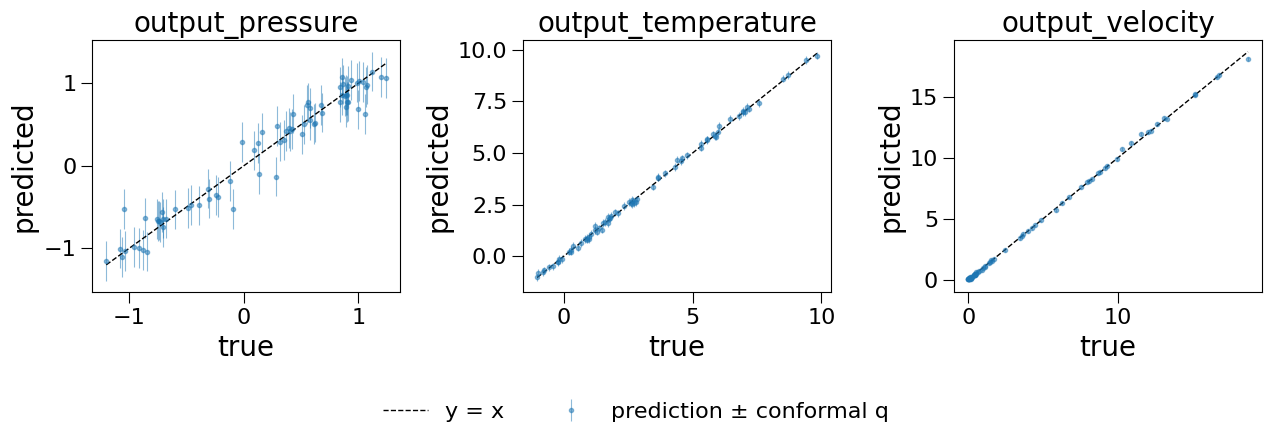

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, bundle["output_columns"]):
    ax.errorbar(new_rows[name], pred[name], yerr=q[name], fmt="o", ms=3, alpha=0.5,
                elinewidth=0.8, label=f"prediction ± conformal q")
    lims = [min(new_rows[name].min(), pred[name].min()), max(new_rows[name].max(), pred[name].max())]
    ax.plot(lims, lims, "k--", lw=1, label="y = x")
    ax.set(title=name, xlabel="true", ylabel="predicted")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 0.0), frameon=False)

---
<a id='missing'></a>
## 6. Rows with Missing Inputs

The `imputer` step lets the pipeline take rows with empty input cells, even if the
training data had none. Here three of the new rows lose one value each:

In [14]:
gappy = new_rows[INPUTS].head(3).copy()
gappy.iloc[0, 1] = np.nan
gappy.iloc[1, 3] = np.nan
gappy.iloc[2, 4] = np.nan
upto_imputer = pipe[: [name for name, _ in pipe.steps].index("imputer") + 1]
filled = pd.DataFrame(upto_imputer.transform(gappy), columns=INPUTS, index=gappy.index)
pd.DataFrame([
    {"row": i, "column": col, "filled in": filled.loc[i, col], "true value": new_rows.loc[i, col]}
    for i, col in gappy.isna().stack().loc[lambda s: s].index
])

,row,column,filled in,true value
0,208,feature_1,0.334,1.744
1,188,feature_3,-1.715,1.978
2,12,feature_4,-0.793,-1.314


In [15]:
pd.DataFrame({
    "complete row": pipe.predict(new_rows[INPUTS].head(3))[:, 0],
    "row with a gap": pipe.predict(gappy)[:, 0],
}, index=gappy.index).rename_axis(f"{OUTPUTS[0]} prediction")

,complete row,row with a gap
output_pressure prediction,,
208,0.421,0.341
188,-1.005,-1.046
12,-0.669,-0.667


`upto_imputer` is a slice of the pipeline: the steps up to and including `imputer`.
Slicing a pipeline like this is how you look at what any intermediate step does.

A filled-in value is an estimate. Its quality depends on how well the other inputs
predict the missing one. In this sample the five inputs were drawn independently, so the
neighbours carry little information and the filled values are rough. Treat predictions
for rows with gaps as less reliable than predictions for complete rows. The conformal
intervals were calibrated on complete rows only.

---
<a id='sweep'></a>
## 7. A What-If Sweep

A surrogate is cheap to call, so you can explore it. Below, `feature_0` is swept across its
training range while the other inputs are held at their training medians, and each
output is plotted with its conformal band. Stay inside the training range: predictions
outside it are extrapolation, and the intervals no longer apply.

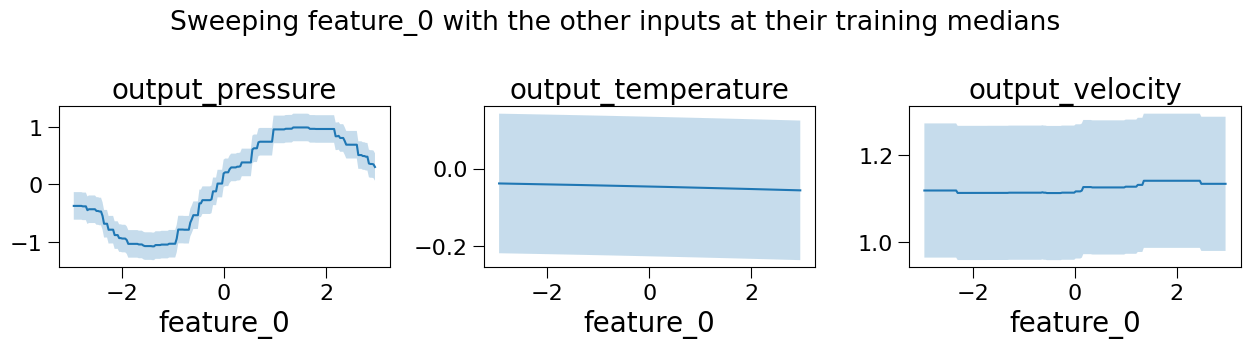

In [16]:
grid = pd.DataFrame({c: np.full(200, sample[c].median()) for c in INPUTS})
grid["feature_0"] = np.linspace(sample["feature_0"].min(), sample["feature_0"].max(), 200)
sweep = pd.DataFrame(pipe.predict(grid), columns=bundle["output_columns"])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, bundle["output_columns"]):
    ax.plot(grid["feature_0"], sweep[name])
    ax.fill_between(grid["feature_0"], sweep[name] - q[name], sweep[name] + q[name], alpha=0.25)
    ax.set(title=name, xlabel="feature_0")
fig.suptitle("Sweeping feature_0 with the other inputs at their training medians")
fig.tight_layout()

Only `output_pressure` responds to `feature_0`. The other two outputs stay flat, which
tells you they depend on the other inputs instead. Sweeping one input at a time like this
is a quick way to see what drives each output.

The same pattern works for optimisation. Any optimiser that calls a function of the
inputs, such as `scipy.optimize.minimize` or `differential_evolution`, can call
`pipe.predict` on a one-row DataFrame.

---
<a id='rebuild'></a>
## 8. Rebuilding the Model from the JSON Config

The `.joblib` file is the trained model. The `.json` file is the recipe for it. Use the
recipe when:

- you have more or newer data and want to **refit** the winning configuration without
  rerunning the whole grid search, or
- the `.joblib` will not load because your package versions differ from the ones it was
  saved with.

Each entry in `config["models"]` names a candidate from `default_surrogate_defs()` and
gives its hyperparameters. Some values are not JSON: a GP kernel is stored as its
`repr`, and a tuple becomes a list. So each value is matched against the candidate's
grid instead of being passed in as is:

In [17]:
def _as_json(value):
    return json.loads(json.dumps(value, default=repr))


def estimator_from_config(entry):
    # Return an unfitted estimator for one entry of config["models"].
    defs = {name: (factory, grid) for name, factory, grid in default_surrogate_defs()}
    factory, grid = defs[entry["model"]]
    wanted = {k: v for k, v in entry.items() if k != "model"}
    for params in ParameterGrid(grid):
        if _as_json(params) == wanted:
            return factory(**params)
    raise ValueError(f"{entry} is not in the grid of {entry['model']!r}")


def pipeline_from_config(config):
    # Unfitted pipeline with the same steps as the exported one.
    from sklearn.decomposition import PCA
    from sklearn.impute import KNNImputer
    from sklearn.pipeline import Pipeline, make_pipeline
    from sklearn.preprocessing import StandardScaler

    from multioutreg.gui.grid_search_core import InputColumnSelector, PerTargetRegressorWithStd

    steps = [("columns", InputColumnSelector(config["input_columns"]))]
    imp = config["preprocessing"]["imputer"]
    if imp is not None:
        steps.append(("imputer", KNNImputer(n_neighbors=imp["n_neighbors"],
                                            keep_empty_features=True)))
    pca = config["preprocessing"]["pca"]
    if pca is not None:
        steps.append(("pca", make_pipeline(StandardScaler(), PCA(n_components=pca["n_components"]))))
    steps.append(("model", PerTargetRegressorWithStd(
        [estimator_from_config(e) for e in config["models"]])))
    return Pipeline(steps)


rebuilt = pipeline_from_config(config)
rebuilt

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columns', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['feature_0', 'feature_1', ...]"
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0`... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'
,"metric metric: {'nan_euclidean'} or callable, default='nan_euclidean'Distance metric for searching neighbors. Possible values:- 'nan_euclidean'- callable : a user-defined function which conforms to the definition of ``func_metric(x, y, *, missing_values=np.nan)``. `x` and `y` corresponds to a row (i.e. 1-D arrays) of `X` and `Y`, respectively. The callable should returns a scalar distance value.",'nan_euclidean'
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.",True


Fit it on the same rows the app trained on, and compare with the exported model:

In [18]:
train_rows, _ = train_test_split(sample, test_size=0.25, random_state=0)
train_rows, _ = train_test_split(train_rows, test_size=config["data_split"]["calibration_fraction"],
                                 random_state=0)
rebuilt.fit(train_rows, train_rows[config["output_columns"]].values)

refit_pred = rebuilt.predict(new_inputs)
diff = np.abs(pred.values - refit_pred)
pd.DataFrame({"model": [m["model"] for m in config["models"]],
              "mean |exported - rebuilt|": diff.mean(axis=0),
              "max |exported - rebuilt|": diff.max(axis=0),
              "std of the output": new_rows[config["output_columns"]].std().values},
             index=config["output_columns"])

,model,mean |exported - rebuilt|,max |exported - rebuilt|,std of the output
output_pressure,xgb,0.000,0.000,0.733
output_temperature,pbr,0.000,0.000,2.800
output_velocity,et,0.046,0.323,5.254


Models that are deterministic or have a fixed seed come back identical. Several of the
tree-ensemble candidates (`rf`, `et`, `gb`) have no fixed seed, so each fit grows slightly
different trees. If one of them won, its rebuilt predictions differ a little from the
exported ones but are equally good. For the exact exported model, use the `.joblib`.
(The same randomness means a rerun of the app can occasionally pick a different winner
for an output where two candidates scored almost the same.)

Refitting on new data works the same way: call `rebuilt.fit(new_df, new_df[outputs].values)`.

Two caveats:

- **The conformal quantiles do not carry over.** They belong to the exported model. After
  refitting, recalibrate on rows the refit did not use: take the absolute residuals on
  those rows and compute `BaseConformalPredictor._conformal_quantile(residuals, alpha)`
  for each output, as `make_app_download` does above.
- **The config only rebuilds candidates that are installed.** Models such as `lgbm`,
  `xgb`, `catboost`, `gpx` and `kpls` come from optional extras. If the winner needs one,
  install that extra first.

---
<a id='caveats'></a>
## 9. Things to Know Before Sharing the File

- **It contains your training inputs.** The KNN imputer stores the training rows, and so
  do GP-type and nearest-neighbour models. Treat the `.joblib` like the dataset it was
  trained on. The `.json` config contains no data.
- **It is a pickle.** Anyone who loads it runs whatever it contains. Share it only with
  people who trust you, and load only files from sources you trust.
- **Versions matter.** Keep the `versions` from the config alongside the file. If a
  future environment can't load it, rebuild from the config (section 8).
- **It answers for the training distribution only.** Inputs outside the training range,
  or rows where many cells were filled in, give predictions the reported metrics and
  conformal coverage do not cover.